In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv("LAB1_processed_data.csv")
print("Full file shape:", df.shape)

cols = ["Pregnant", "Glucose", "Diastolic_BP", "Skin_Fold",
        "Serum_Insulin", "BMI", "Diabetes_Pedigree", "Age", "Class"]
data = df[cols]

features = cols[:-1]
target = "Class"

print("Working shape:", data.shape)
data.head()

Full file shape: (768, 25)
Working shape: (768, 9)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Pregnant                768 non-null    int64  
 1   Glucose                 768 non-null    float64
 2   Diastolic_BP            768 non-null    float64
 3   Skin_Fold               768 non-null    float64
 4   Serum_Insulin           768 non-null    float64
 5   BMI                     768 non-null    float64
 6   Diabetes_Pedigree       768 non-null    float64
 7   Age                     768 non-null    int64  
 8   Class                   768 non-null    int64  
 9   Pregnant_std            768 non-null    float64
 10  Glucose_std             768 non-null    float64
 11  Diastolic_BP_std        768 non-null    float64
 12  Skin_Fold_std           768 non-null    float64
 13  Serum_Insulin_std       768 non-null    float64
 14  BMI_std                 768 non-null    float64
 15  

In [17]:
stats = data[features].describe().T
stats["median"] = data[features].median()
stats["variance"] = data[features].var()
stats["skewness"] = data[features].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
Pregnant,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00,3.00,11.35,0.90
Glucose,768.0,121.69,30.44,44.00,99.75,117.00,140.25,199.00,117.00,926.35,0.53
Diastolic_BP,768.0,72.41,12.10,24.00,64.00,72.20,80.00,122.00,72.20,146.32,0.14
Skin_Fold,768.0,29.11,8.79,7.00,25.00,29.00,32.00,99.00,29.00,77.29,0.84
Serum_Insulin,768.0,140.67,86.38,14.00,121.50,125.00,127.25,846.00,125.00,7462.03,3.38
BMI,768.0,32.46,6.88,18.20,27.50,32.40,36.60,67.10,32.40,47.27,0.60
Diabetes_Pedigree,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42,0.37,0.11,1.92
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00,29.00,138.30,1.13


In [25]:
print("Class counts:")
print(data["Class"].value_counts())

print("\nAverage of each feature by class:")
data.groupby(target)[features].mean().round(2)

Class counts:
Class
0    500
1    268
Name: count, dtype: int64

Average of each feature by class:


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age
Class,,,,,,,,
0,3.30,110.71,70.94,27.73,127.79,30.89,0.43,31.19
1,4.87,142.17,75.15,31.69,164.70,35.38,0.55,37.07


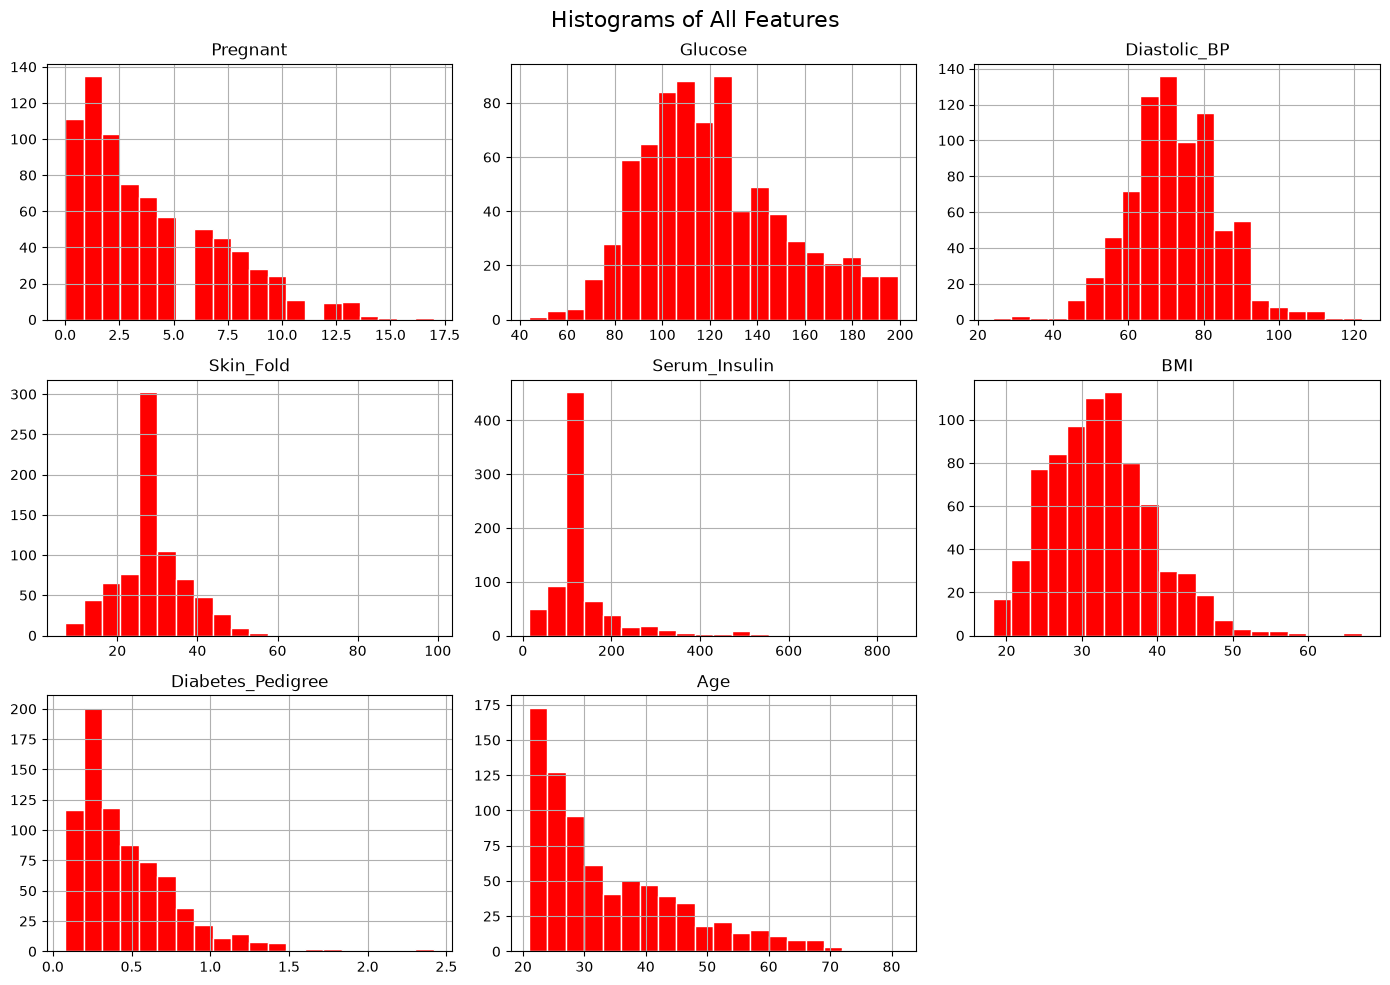

In [26]:
data[features].hist(bins=20, figsize=(14, 10), color="red", edgecolor="white")
plt.suptitle("Histograms of All Features", fontsize=16)
plt.tight_layout()
plt.show()

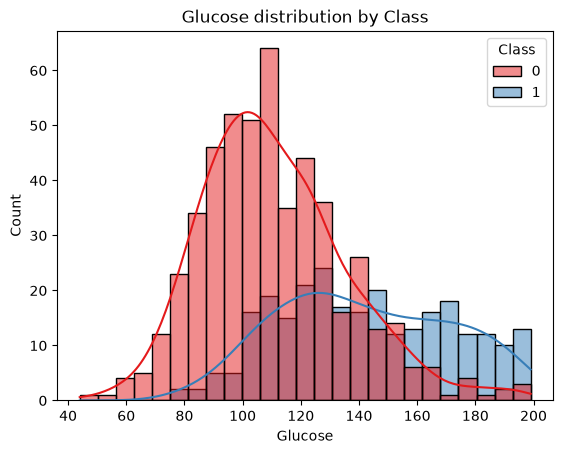

In [20]:
sns.histplot(data=data, x="Glucose", hue="Class", kde=True, bins=25, palette="Set1")
plt.title("Glucose distribution by Class")
plt.show()

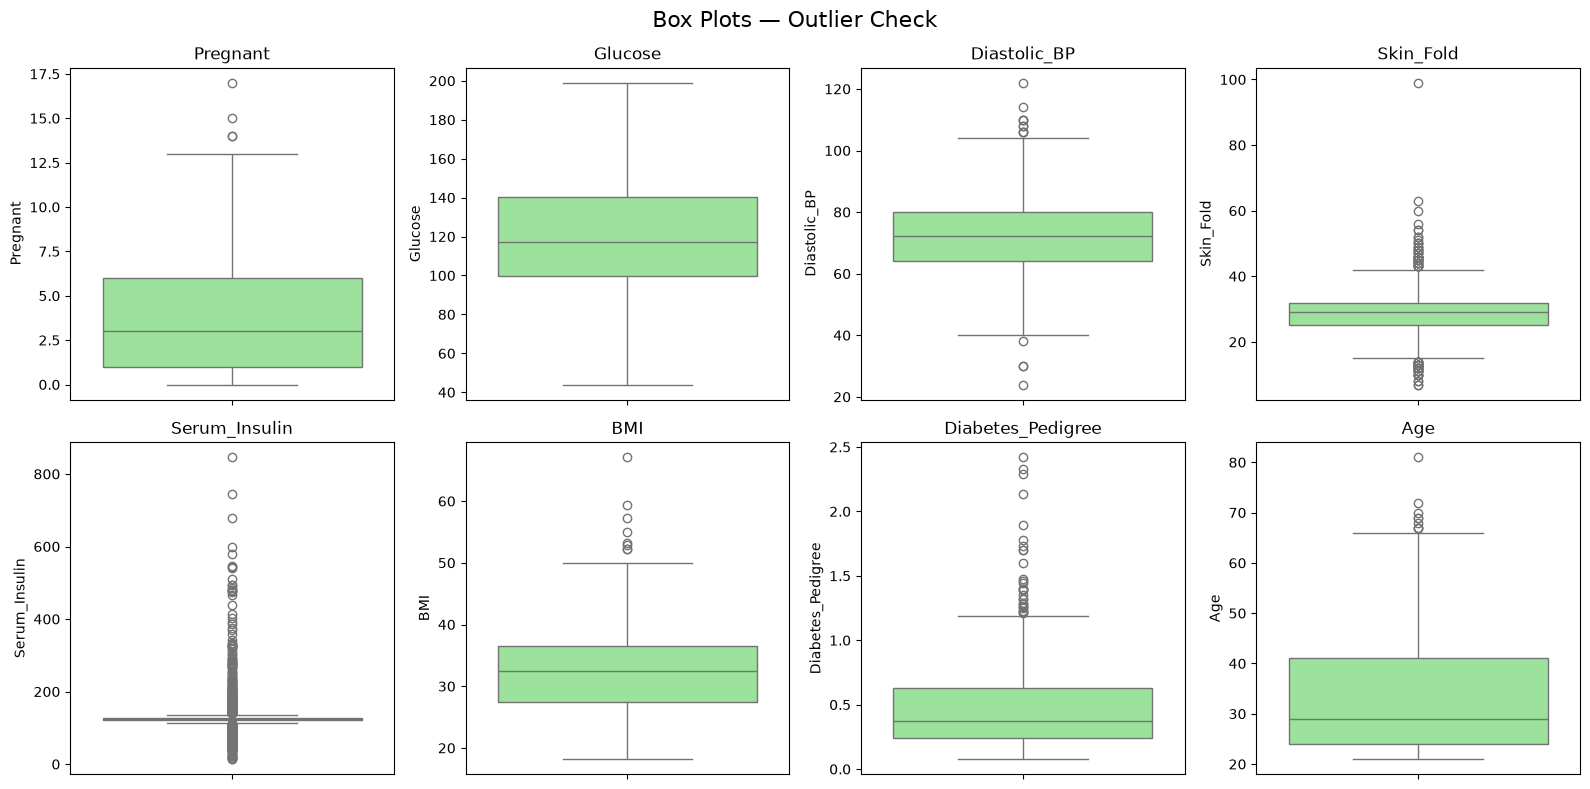

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=data[col], ax=ax, color="lightgreen")
    ax.set_title(col)

plt.suptitle("Box Plots — Outlier Check", fontsize=16)
plt.tight_layout()
plt.show()

In [22]:
corr = data.corr()
corr.round(2)

,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
Pregnant,1.00,0.13,0.21,0.08,0.03,0.02,-0.03,0.54,0.22
Glucose,0.13,1.00,0.22,0.19,0.42,0.23,0.14,0.27,0.49
Diastolic_BP,0.21,0.22,1.00,0.19,0.05,0.28,-0.00,0.32,0.17
Skin_Fold,0.08,0.19,0.19,1.00,0.16,0.54,0.10,0.13,0.21
Serum_Insulin,0.03,0.42,0.05,0.16,1.00,0.18,0.13,0.10,0.20
BMI,0.02,0.23,0.28,0.54,0.18,1.00,0.15,0.03,0.31
Diabetes_Pedigree,-0.03,0.14,-0.00,0.10,0.13,0.15,1.00,0.03,0.17
Age,0.54,0.27,0.32,0.13,0.10,0.03,0.03,1.00,0.24
Class,0.22,0.49,0.17,0.21,0.20,0.31,0.17,0.24,1.00


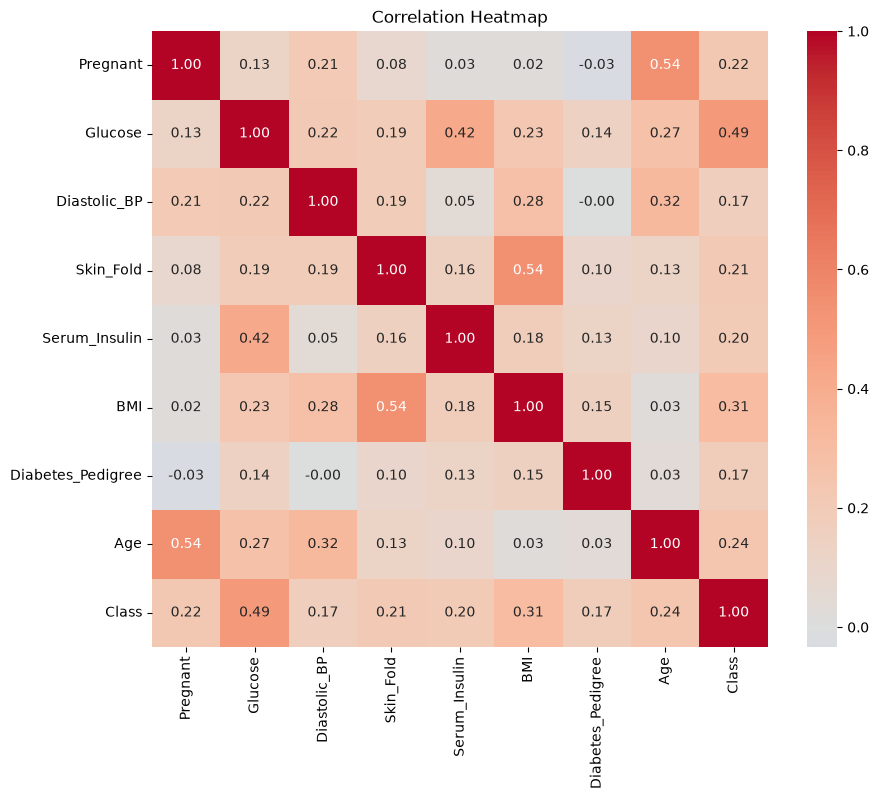

In [29]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.show()

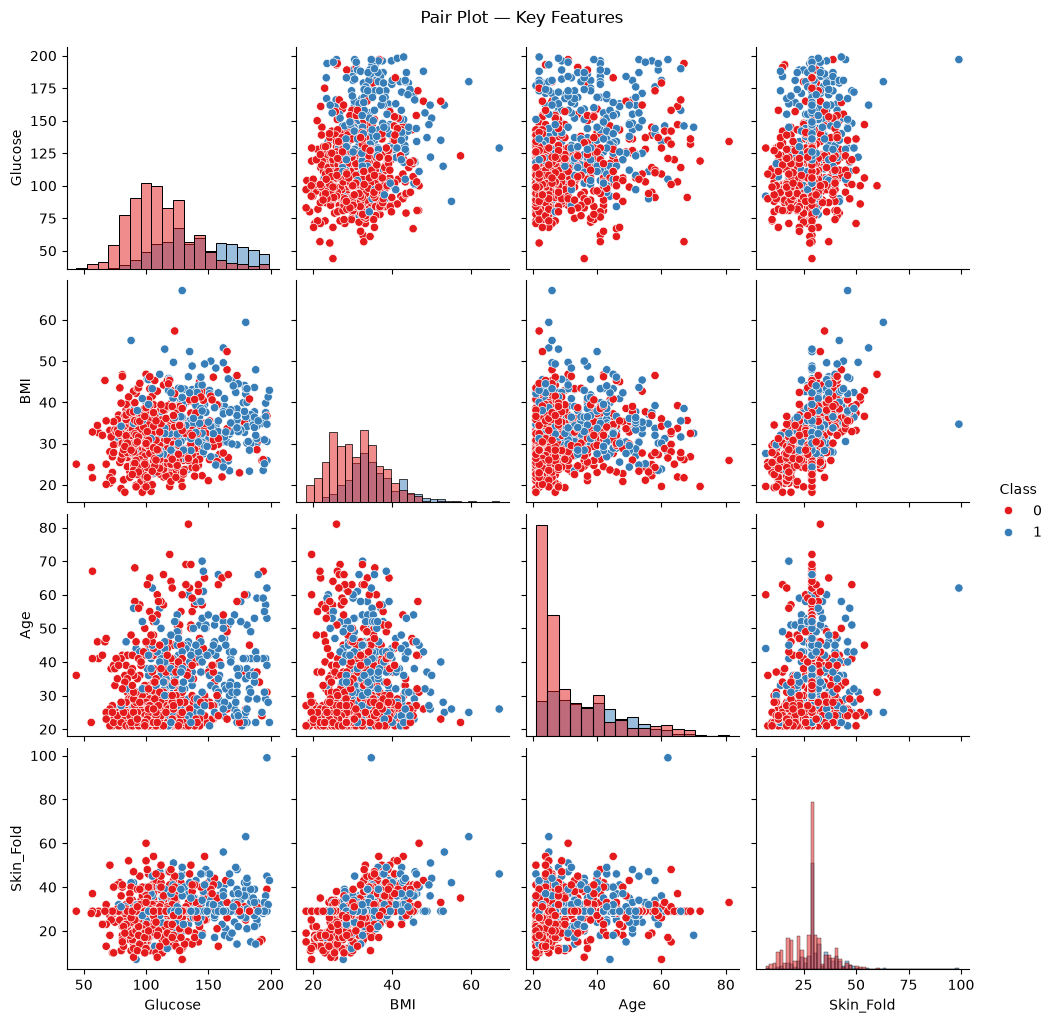

In [24]:
small = ["Glucose", "BMI", "Age", "Skin_Fold", "Class"]

sns.pairplot(data[small], hue="Class", palette="Set1", diag_kind="hist")
plt.suptitle("Pair Plot — Key Features", y=1.02)
plt.show()